# Lecture 22 Worksheet: How a Network Learns
**NAVTTC / NIAI AI/ML Trainer Cohort** — works in Google Colab (TensorFlow is already installed there).

Fill every `___` blank, run the cells top to bottom. Each task has a check line that prints `OK` when your answer is right.

In [1]:
import numpy as np, matplotlib.pyplot as plt
def sigmoid(z): return 1 / (1 + np.exp(-z))

# Six made-up delivery orders: x = delivery time in tens of minutes, y = 5-star review (1) or not (0)
x = np.array([1.5, 2.2, 2.8, 3.5, 4.5, 5.5])
y = np.array([1,   1,   0,   1,   0,   0  ])

## Task 1: Cross-entropy loss for one example
`L = -( y*ln(a) + (1-y)*ln(1-a) )`. Fill in the function and check it against the slide.

In [2]:
def loss(y, a):
    return -(y * np.log(a) + (1 - y) * np.log(1 - a))

print(round(loss(1, 0.9), 3), round(loss(1, 0.5), 3), round(loss(1, 0.1), 3), round(loss(0, 0.1), 3))
assert abs(loss(1, 0.9) - 0.105) < 0.001 and abs(loss(1, 0.1) - 2.303) < 0.001 and abs(loss(0, 0.1) - 0.105) < 0.001; print("OK")

0.105 0.693 2.303 0.105
OK


**Think:** why is the loss for `y=1, a=0.01` (about 4.6) so much bigger than for `y=1, a=0.5`? Write your answer: ______

## Task 2: The cost J at the start
With `w = 0` and `b = 0` every answer is 0.5. What is the cost J (the average loss)?

In [3]:
def cost(w, b):
    a = sigmoid(w * x + b)
    return np.mean(loss(y, a))

J0 = cost(0.0, 0.0)
print(round(J0, 3))
assert abs(J0 - 0.693) < 0.001; print("OK")

0.693
OK


## Task 3: One gradient descent step by hand (slide 10)
`dw = mean((a - y) * x)`, `db = mean(a - y)`. Then `w = w - alpha*dw`.

In [4]:
w, b, alpha = 0.0, 0.0, 0.5
a = sigmoid(w * x + b)
dw = np.mean((a - y) * x)
db = np.mean(a - y)
w_new, b_new = w - alpha * dw, b - alpha * db
print(round(dw, 3), round(db, 3), round(w_new, 3), round(b_new, 3), "new cost:", round(cost(w_new, b_new), 3))
assert abs(dw - 0.467) < 0.001 and abs(db) < 1e-9 and abs(w_new + 0.233) < 0.001 and abs(cost(w_new, b_new) - 0.669) < 0.001; print("OK")

0.467 0.0 -0.233 0.0 new cost: 0.669
OK


## Task 4: The full training loop
Repeat forward, gradient, update 2000 times. Then compare with scikit-learn's LogisticRegression.

w = -1.63  b = 5.3  cost = 0.402


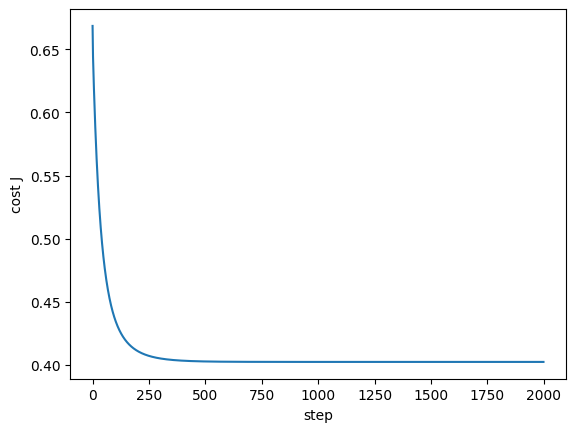

OK
scikit-learn: [-1.64] [5.3]


In [5]:
w, b, alpha = 0.0, 0.0, 0.5
history = []
for step in range(2000):
    a  = sigmoid(w * x + b)
    dw = np.mean((a - y) * x)
    db = np.mean(a - y)
    w  = w - alpha * dw
    b  = b - alpha * db
    history.append(cost(w, b))

print("w =", round(w, 2), " b =", round(b, 2), " cost =", round(history[-1], 3))
plt.plot(history); plt.xlabel("step"); plt.ylabel("cost J"); plt.show()
assert abs(w + 1.63) < 0.02 and abs(b - 5.30) < 0.05; print("OK")

from sklearn.linear_model import LogisticRegression
m = LogisticRegression(C=1e6).fit(x.reshape(-1, 1), y)
print("scikit-learn:", m.coef_.ravel().round(2), m.intercept_.round(2))

**Think:** the scikit-learn weights should match yours. Why? ______

## Task 5: The learning rate
Run the loop for several values of alpha (100 steps each) and print the final cost.

In [6]:
def run(alpha, steps=100):
    w = b = 0.0
    for _ in range(steps):
        a = np.clip(sigmoid(w * x + b), 1e-12, 1 - 1e-12)
        w, b = w - alpha * np.mean((a - y) * x), b - alpha * np.mean(a - y)
    a = np.clip(sigmoid(w * x + b), 1e-12, 1 - 1e-12)
    return float(np.mean(loss(y, a)))

for alpha in [0.01, 0.3, 1, 10]:
    print(alpha, round(run(alpha), 3))
assert run(0.01) > 0.6 and run(0.3) < run(0.01) and run(10) > run(1); print("OK")
best_alpha = 1      # which of the four gave the lowest cost after 100 steps?

0.01 0.65
0.3 0.47
1 0.408
10 2.249
OK


## Task 6: Backpropagation by hand on a tiny network
x = 1, hidden neuron (w1 = 0.5, b1 = 0), output neuron (w2 = -1, b2 = 0.5), true answer y = 1.

In [7]:
x0, y0 = 1.0, 1.0
w1, b1, w2, b2 = 0.5, 0.0, -1.0, 0.5

# forward
z1 = w1 * x0 + b1;  a1 = sigmoid(z1)
z2 = w2 * a1 + b2;  a2 = sigmoid(z2)
L  = float(loss(y0, a2))
print("a1, a2, L =", round(a1, 3), round(a2, 3), round(L, 3))
assert abs(a2 - 0.469) < 0.001 and abs(L - 0.756) < 0.001; print("OK forward")

# backward (right to left)
dz2 = a2 - y0
dw2 = dz2 * a1;   db2 = dz2
da1 = dz2 * w2                     # pass the blame through w2
dz1 = da1 * a1 * (1 - a1)           # multiply by the sigmoid slope
dw1 = dz1 * x0;   db1 = dz1
print("dw2, db2, dw1, db1 =", round(dw2, 3), round(db2, 3), round(dw1, 3), round(db1, 3))
assert abs(dw2 + 0.330) < 0.001 and abs(dw1 - 0.125) < 0.001; print("OK backward")

a1, a2, L = 0.622 0.469 0.756
OK forward
dw2, db2, dw1, db1 = -0.33 -0.531 0.125 0.125
OK backward


Now check the gradient with a **numerical gradient** (nudge w1 by a tiny amount and watch the loss).

In [8]:
def L_of(w1, b1, w2, b2):
    a1 = sigmoid(w1 * x0 + b1); a2 = sigmoid(w2 * a1 + b2)
    return float(loss(y0, a2))

eps = 1e-6
num_dw1 = (L_of(w1 + eps, b1, w2, b2) - L_of(w1 - eps, b1, w2, b2)) / (2 * eps)
print("numerical:", round(num_dw1, 6), " backprop:", round(dw1, 6))
assert abs(num_dw1 - dw1) < 1e-5; print("OK, backprop is correct")

alpha = 0.5
new_L = L_of(w1 - alpha*dw1, b1 - alpha*db1, w2 - alpha*dw2, b2 - alpha*db2)
print("loss before:", round(L, 3), " after one step:", round(new_L, 3))
assert new_L < L; print("OK, the loss went down")

numerical: 0.124687  backprop: 0.124687
OK, backprop is correct
loss before: 0.756  after one step: 0.567
OK, the loss went down


**Think:** change `y0` to 0 and rerun Task 6. Which gradients change sign, and why? ______

## Task 7: Let TensorFlow compute the gradient

In [9]:
import tensorflow as tf
xt = tf.constant(x, dtype=tf.float32); yt = tf.constant(y, dtype=tf.float32)
wv = tf.Variable(0.0); bv = tf.Variable(0.0)
with tf.GradientTape() as tape:
    a = tf.sigmoid(wv * xt + bv)
    J = -tf.reduce_mean(yt * tf.math.log(a) + (1 - yt) * tf.math.log(1 - a))
dw_tf, db_tf = tape.gradient(J, [wv, bv])
print(dw_tf.numpy(), db_tf.numpy())
assert abs(dw_tf.numpy() - 0.4667) < 0.001 and abs(db_tf.numpy()) < 1e-6; print("OK, same as our hand gradient")

0.46666667 0.0
OK, same as our hand gradient


## Task 8: Train a Keras network on all ten digits and read the curves

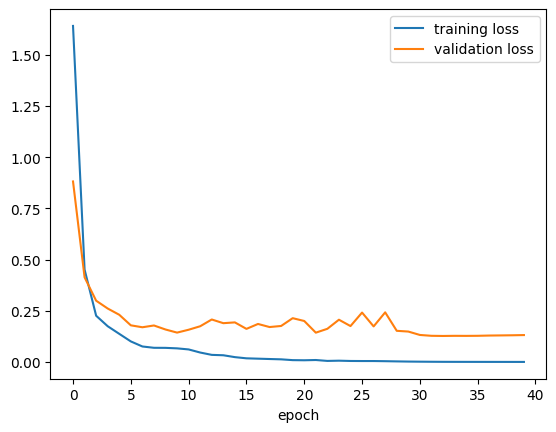

test accuracy: 0.969
OK


In [10]:
from tensorflow.keras import layers
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
d = load_digits(); X = d.data / 16.0; Y = d.target
Xtr, Xte, ytr, yte = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

tf.keras.utils.set_random_seed(1)
model = tf.keras.Sequential([
    tf.keras.Input(shape=(64,)),
    layers.Dense(25, activation="relu"),
    layers.Dense(15, activation="relu"),
    layers.Dense(10, activation="softmax"),     # one neuron per digit
])
model.compile(loss="sparse_categorical_crossentropy", optimizer=tf.keras.optimizers.Adam(0.01), metrics=["accuracy"])
h = model.fit(Xtr, ytr, epochs=40, batch_size=32, validation_split=0.2, verbose=0)

plt.plot(h.history["loss"], label="training loss"); plt.plot(h.history["val_loss"], label="validation loss")
plt.xlabel("epoch"); plt.legend(); plt.show()
test_acc = model.evaluate(Xte, yte, verbose=0)[1]
print("test accuracy:", round(test_acc, 3))
assert test_acc > 0.9; print("OK")

**Think:** compare the two curves. Is the validation loss still falling when the training loss is almost 0? What does that tell you? ______

## Task 9: About your own project (answer in your own words)
1. Is your project a yes/no, a choice among classes, or a number? Which loss and output layer would you use?
2. Which learning rate would you try first, and how would you know it is wrong?
3. Describe in two sentences what 'backpropagation' does, without using the word 'derivative'.

Your answers: ______

## Bonus: plain SGD vs Adam
Train the same network with `tf.keras.optimizers.SGD(0.1)` for 20 epochs and compare the validation accuracy with Adam. Which learns faster? Why do you think so?

In [11]:
def train(opt, epochs=20):
    tf.keras.utils.set_random_seed(1)
    m = tf.keras.Sequential([tf.keras.Input(shape=(64,)), layers.Dense(25, activation="relu"), layers.Dense(15, activation="relu"), layers.Dense(10, activation="softmax")])
    m.compile(loss="sparse_categorical_crossentropy", optimizer=opt, metrics=["accuracy"])
    return m.fit(Xtr, ytr, epochs=epochs, batch_size=32, validation_split=0.2, verbose=0)

h_sgd  = train(tf.keras.optimizers.SGD(0.1))
h_adam = train(tf.keras.optimizers.Adam(0.01))
print("SGD  val acc after 20 epochs:", round(h_sgd.history["val_accuracy"][-1], 3))
print("Adam val acc after 20 epochs:", round(h_adam.history["val_accuracy"][-1], 3))

SGD  val acc after 20 epochs: 0.924
Adam val acc after 20 epochs: 0.924


## Wrap-up
- Loss says how wrong; gradient says which way; learning rate says how far.
- Backpropagation = chain rule from the output back, to get every gradient.
- Keras `compile` + `fit` run the whole loop; TensorFlow's autodiff does the backprop.
- Next: why a network can fit the training data too well, and how to stop it (Lecture 23).